Task: For small $n$ and $q$, implement an exhaustive secret search, i.e., for every candidate $s'$, calculate $\vec{r}=\vec{b}-{\bf A}\vec{s}'$ and convert the residues to their centered representatives. Does an attacker gain advantage from knowing the true error distribution?

**This file will be rather heavily created with Copilot.** Sorry): All the following cells are Copilot-made.

In [28]:
# Creating a toy LWE oracle

from sage.crypto.lwe import LWE
from sage.probability.probability_distribution import RealDistribution
# Toy parameters
n = 6
q = 17
m = 20
# Rounded Gaussian sampler
class CustomSampler:
    def __init__(self, D):
        self.D = D
    def __call__(self):
        return round(self.D.get_random_element())
D = RealDistribution('exppow', [1, 8])
lwe = LWE(
    n=n,
    q=q,
    D=CustomSampler(D),
    secret_dist='uniform',
    m=None
)

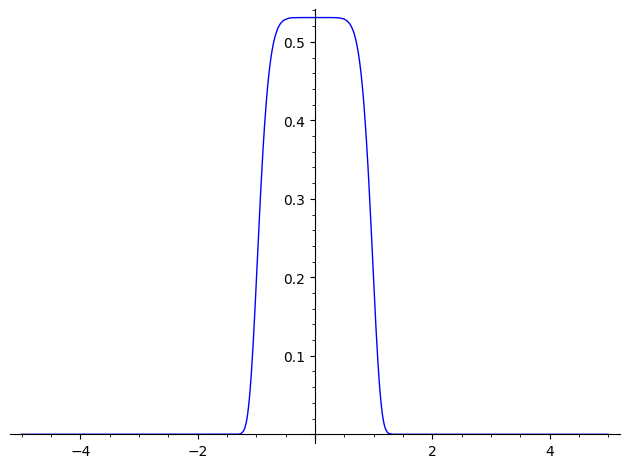

In [29]:
D.plot([-5,5])

In [30]:
# Get true s for comparison
s_true = lwe._LWE__s
print("True secret:", s_true)

True secret: (10, 9, 5, 16, 6, 14)


In [31]:
# Generate samples
S = [lwe() for _ in range(m)]
# Split into matrix-vector forms
Rq = Zmod(q)
A = matrix(Rq, [sample[0] for sample in S])
b = vector(Rq, [sample[1] for sample in S])
print("A dimensions:", A.dimensions())
print("b length:", len(b))

A dimensions: (20, 6)
b length: 20


In [32]:
# Centering
def centered(x, q):
    x = int(x) % q
    if x > q//2:
        x -= q
    return x

In [33]:
# Scoring based on residual: For Gaussian errors the ML score is equivalent to minimizing \sum_i r_i^2
def residual_norm_squared(r):
    return sum(x*x for x in r)

In [34]:
r = [4, 2, 7]

In [35]:
residual_norm_squared(r)

69

In [36]:
from itertools import product
len(list(product(range(q), repeat=n)))

24137569

In [37]:
# Exhaustive search
best_s = None
best_score = Infinity
print(f'have to look through {len(list(product(range(q), repeat=n)))} combinations')
for coords in product(range(q), repeat=n):
    s_candidate = vector(Rq, coords)
    r = b - A*s_candidate
    r_centered = [centered(x, q) for x in r]
    score = residual_norm_squared(r_centered)
    if score < best_score:
        best_score = score
        best_s = s_candidate

print("Recovered secret:", best_s)
print("Best score:", best_score)

have to look through 24137569 combinations
Recovered secret: (10, 9, 5, 16, 6, 14)
Best score: 8


In [38]:
# Compare with truth
print("True secret     :", s_true)
print("Recovered secret:", best_s)
print("Success:", s_true == best_s)

True secret     : (10, 9, 5, 16, 6, 14)
Recovered secret: (10, 9, 5, 16, 6, 14)
Success: True


In [ ]:
# Inspect top candidates
scores = []
for coords in product(range(q), repeat=n):
    s_candidate = vector(Rq, coords)
    r = b - A*s_candidate
    r_centered = [centered(x, q) for x in r]
    score = residual_norm_squared(r_centered)
    scores.append((score, s_candidate))

scores.sort()
for score, secret in scores[:10]:
    print(score, secret)

In [ ]:
# Testing different error distributions: replace D with following lines:
D = RealDistribution('uniform', [-3,3])
D = RealDistribution('t', 2)
D = RealDistribution('exppow', [1,4])

Possible research questions:
- does a different error distribution imply a different optimization to apply for the breaking?

supervisor agrees that this maybe could be done with lattice estimator instead of naive

maybe put as a part of the report the comparison of naive vs doing the proper things. also maybe try to describe better what the $\alpha$ is doing (w.r.t. difficulty of solving the challenge)